# Week 7 guided lab · Wales from a map and from space

**CMT124** · one-hour **guided** lab

**The question:** where are Wales's operational wind and solar farms, and what can a satellite tell us about the land around them?

You'll answer it with this week's three tools, one after the other: an interactive **Folium** map of the projects, a **seaborn** chart of satellite pixels, and an **NDVI** layer from Earth Engine on the same map.

### How this guided lab works

As in Week 6, **we work through it together, one step at a time.**

| Each step has | What you do |
|---|---|
| **Do** | one operation, in the empty code cell |
| **Checkpoint** | run the checkpoint cell and compare what it prints (or draws) with your neighbours |
| **Think** | a question we answer together; jot down the answer in the notes cell |

* Only one step is open at a time. Finished early? Read the next **Think** question and prepare an answer.
* A checkpoint that prints `✔` means your result matches. An `AssertionError` tells you what to look at.
* Stuck? Under the key steps there is a cell headed *"If your result does not match the checkpoint, run this cell to continue."* Run it and carry on with everyone else; come back to your own version later.
* Everything uses skills from Weeks 6 and 7: filtering with `&` and `isin`, `value_counts`, Folium `Map` / `FeatureGroup` / `CircleMarker` / `LayerControl`, column arithmetic, `sns.boxplot`, `groupby`, and the Earth Engine steps of Hour 3.
* **No Earth Engine access?** Every step works without it. Step 5 has two routes that lead to the same question.

| Step | One operation | Checkpoint |
|---|---|---|
| 1 | keep Wales's operational wind and solar projects | counts per technology |
| 2 | an interactive map with one layer per technology | markers per layer, and the map |
| 3 | satellite pixels as a table: NDVI by band maths | your NDVI matches the supplied one |
| 4 | does NDVI tell surfaces apart? A seaborn boxplot | median NDVI per land cover |
| 5 | satellite NDVI and the projects on one map | a map (with Earth Engine) or the figure from class |

### Setup

Run this cell first.

*Data: Renewable Energy Planning Database, Q2 July 2025, Department for Energy Security and Net Zero; contains public sector information licensed under the Open Government Licence v3.0. Satellite pixel table: contains modified Copernicus Sentinel data 2021, processed in Google Earth Engine; land cover from ESA WorldCover 10 m 2021 v200 (Zanaga et al. 2022), CC BY 4.0.*

In [ ]:
# --- Setup: run this cell first -------------------------------------------------
# Course datasets live in the course repository under 2026-27/datasets/.
# get_data() uses a local copy if the notebook runs inside a copy of the repository;
# otherwise (e.g. in Google Colab) it downloads the file once and reuses it.
import os
import urllib.request

COURSE_REPO = "OWNER/REPO"
BASE_URL = f"https://raw.githubusercontent.com/{COURSE_REPO}/main/2026-27/"


def course_file(relpath):
    """Return a local path to a course file such as 'datasets/owid_co2_cleaned.csv'."""
    for root in ("../../..", "."):                     # 1) running inside a copy of the repository
        path = os.path.join(root, relpath)
        if os.path.exists(path):
            return path
    path = os.path.join("course_files", relpath)       # 2) Colab: download once
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        urllib.request.urlretrieve(BASE_URL + relpath, path)
    return path


def get_data(name):
    """Return a local path to a course dataset, e.g. get_data('owid_co2_cleaned.csv')."""
    return course_file("datasets/" + name)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

## Step 1 · Wales's operational wind and solar projects

**Step 1 of 5** · ●○○○○

**Do:** read `"repd_cleaned.csv"` into `repd`. Then keep only the rows where `country` is `"Wales"`, `status` is `"Operational"`, and `technology` is `"Wind Onshore"` or `"Solar Photovoltaics"`. Call the result `wales`.

In [ ]:
# STUDENT TASK
# Task: repd (read_csv), then wales = Welsh, operational, onshore wind or solar projects
# Hint: three conditions joined with &; for the technology use .isin(["Wind Onshore", "Solar Photovoltaics"])
# your code here


### Checkpoint 1

In [ ]:
# Checkpoint 1: compare these numbers with your neighbours
print(wales.shape)
print(wales["technology"].value_counts())
assert len(wales) == 199, "expected 199 projects: check all three conditions (country, status, technology)"
assert set(wales["technology"]) == {"Wind Onshore", "Solar Photovoltaics"}, "keep only the two technologies"
print("✔ Step 1")

In [ ]:
# If your result does not match the checkpoint, run this cell to continue.
repd = pd.read_csv(get_data("repd_cleaned.csv"))
wales = repd[(repd["country"] == "Wales") & (repd["status"] == "Operational")
             & repd["technology"].isin(["Wind Onshore", "Solar Photovoltaics"])]

### Think 1


Solar projects outnumber wind projects **127 to 72**. Does that mean Wales gets more electricity from solar than from onshore wind? Which column would you look at next, and what would it still not tell you?

*Notes from the discussion:*

**Pause.** We compare checkpoints and answer the question together before Step 2 opens.

## Step 2 · An interactive map with one layer per technology

**Step 2 of 5** · ●●○○○

**Do:** the Hour 2 pattern, for Wales.
1. Create `m = folium.Map(location=[52.3, -3.7], zoom_start=8, tiles="OpenStreetMap")`.
2. Make two layers: `wind_layer` (name `"Wind Onshore"`) and `solar_layer` (name `"Solar Photovoltaics"`), each `.add_to(m)`.
3. Loop over the wind rows of `wales` and add one blue `CircleMarker` per project to `wind_layer`, with the project name as tooltip; do the same for the solar rows, in orange, into `solar_layer`.
4. Add a `LayerControl` and show `m`.

In [ ]:
# STUDENT TASK
# Task: m, wind_layer, solar_layer; one CircleMarker per project (tooltip = project name); LayerControl; show m
# Hint: for _, row in wales[wales["technology"] == "Wind Onshore"].iterrows(): folium.CircleMarker([row["lat"], row["lon"]], ...).add_to(wind_layer)
# your code here


### Checkpoint 2

The cell below counts the markers in each layer. On the map, switch each layer off and on: the wind projects (blue) should cluster in **Powys** (mid-Wales) and the **South Wales valleys**; the solar projects (orange) in **Pembrokeshire**, **Carmarthenshire** and the **Vale of Glamorgan**, along the south and west.

In [ ]:
# Checkpoint 2: one marker per project in each layer
n_wind = sum(isinstance(x, folium.CircleMarker) for x in wind_layer._children.values())
n_solar = sum(isinstance(x, folium.CircleMarker) for x in solar_layer._children.values())
print("wind markers:", n_wind, "| solar markers:", n_solar)
assert (n_wind, n_solar) == (72, 127), "expected 72 wind and 127 solar markers: check the filter in each loop"
print("✔ Step 2")

In [ ]:
# If your result does not match the checkpoint, run this cell to continue.
m = folium.Map(location=[52.3, -3.7], zoom_start=8, tiles="OpenStreetMap")
wind_layer = folium.FeatureGroup(name="Wind Onshore").add_to(m)
solar_layer = folium.FeatureGroup(name="Solar Photovoltaics").add_to(m)
for _, row in wales[wales["technology"] == "Wind Onshore"].iterrows():
    folium.CircleMarker([row["lat"], row["lon"]], radius=5, color="blue", fill=True,
                        tooltip=row["project_name"]).add_to(wind_layer)
for _, row in wales[wales["technology"] == "Solar Photovoltaics"].iterrows():
    folium.CircleMarker([row["lat"], row["lon"]], radius=5, color="orange", fill=True,
                        tooltip=row["project_name"]).add_to(solar_layer)
folium.LayerControl().add_to(m);

### Think 2


Wind and solar projects sit in **different parts** of Wales. Suggest one reason for where each technology is built. Why is a map with **switchable layers** better for this question than one map with all 199 markers in one colour?

*Notes from the discussion:*

**Pause.** We compare checkpoints and answer the question together before Step 3 opens.

## Step 3 · Satellite pixels as a table

**Step 3 of 5** · ●●●○○

In Hour 3 we said that sampling a raster turns **pixels into rows** and **bands into columns**. Here is such a table: **4,800 Sentinel-2 pixels** (10 m) from a 2021 cloud-free composite of the area around Cardiff, sampled with Earth Engine and saved as a file, so it works without an account. Values are reflectance × 10,000, as in Hour 3. The `label` column says what each pixel is according to the ESA WorldCover land-cover map; the next cell turns the codes into names (1,200 pixels of each).

Run it first:

In [ ]:
pixels = pd.read_csv(get_data("landcover_cardiff_2021_sample.csv"))
pixels["land_cover"] = pixels["label"].map({0: "other", 1: "vegetation", 2: "urban", 3: "water"})
pixels.head(3)

The table already has an `NDVI` column, computed by Earth Engine. **Do:** compute NDVI **yourself** from the `B8` (NIR) and `B4` (red) columns, as a new column `ndvi_check`: band maths with pandas, one formula for all 4,800 rows.

In [ ]:
# STUDENT TASK
# Task: pixels["ndvi_check"] = NDVI from the B8 and B4 columns
# Hint: (NIR - Red) / (NIR + Red), with whole columns: pixels["B8"], pixels["B4"]
# your code here


### Checkpoint 3

In [ ]:
# Checkpoint 3: your NDVI and Earth Engine's NDVI should agree for every pixel
print(pixels.shape)
print(pixels[["B4", "B8", "NDVI", "ndvi_check"]].head(3).round(3))
largest_gap = (pixels["ndvi_check"] - pixels["NDVI"]).abs().max()
print("largest difference:", largest_gap)
assert pixels.shape == (4800, 11), "expected 4,800 rows: 9 columns from the file + land_cover + ndvi_check"
assert largest_gap < 1e-5, "NDVI = (B8 - B4) / (B8 + B4): check the brackets"
print("✔ Step 3")

In [ ]:
# If your result does not match the checkpoint, run this cell to continue.
pixels = pd.read_csv(get_data("landcover_cardiff_2021_sample.csv"))
pixels["land_cover"] = pixels["label"].map({0: "other", 1: "vegetation", 2: "urban", 3: "water"})
pixels["ndvi_check"] = (pixels["B8"] - pixels["B4"]) / (pixels["B8"] + pixels["B4"])

### Think 3


Each row is one **10 m × 10 m** pixel. The area this sample comes from is roughly 35 km × 33 km. About how many pixels does it contain, and why work with a **sample** of 4,800 instead?

*Notes from the discussion:*

**Pause.** We compare checkpoints and answer the question together before Step 4 opens.

## Step 4 · Does NDVI tell surfaces apart?

**Step 4 of 5** · ●●●●○

**Do:** draw a seaborn **boxplot** of `NDVI` (*y*) for each `land_cover` (*x*), as in Hour 1. Label the *y* axis and give the chart a title that states what you see.

In [ ]:
# STUDENT TASK
# Task: one box of NDVI per land cover, with a y label and a title
# Hint: ax = sns.boxplot(data=pixels, x="land_cover", y="NDVI"), then ax.set_ylabel(...), ax.set_title(...)
# your code here


### Checkpoint 4

Compare your boxes with your neighbours' (the order of the boxes may differ). The **medians** below are the numbers everyone should get.

In [ ]:
# Checkpoint 4: the median NDVI of each land cover
medians = pixels.groupby("land_cover")["NDVI"].median().round(2)
print(medians)
assert medians.to_dict() == {"other": 0.10, "urban": 0.30, "vegetation": 0.72, "water": -0.40}
print("✔ Step 4")

### Think 4


Which land covers does NDVI separate **well**, and which **overlap**? If a computer had only NDVI to decide what a pixel is, where would it make mistakes, and what else in the table could help?

*Notes from the discussion:*

**Pause.** We compare checkpoints and answer the question together before Step 5 opens.

## Step 5 · Satellite NDVI and the projects on one map

**Step 5 of 5** · ●●●●●

Now raster meets vector on one map: the NDVI of summer 2025 under the project markers of Step 2. Two routes lead to the same question:

* **Route A · with Earth Engine.** In the next cell set `USE_EARTH_ENGINE = True`, type your project ID into `EE_PROJECT` and run it. **Do:** build the Hour 3 NDVI for South Wales (a summer 2025 Sentinel-2 median composite over the box given in the hint, clipped to it) and add it to `m` with `add_ee_layer`.
* **Route B · without Earth Engine.** Leave `USE_EARTH_ENGINE = False` and run the next cells anyway. Below them is the NDVI map from class for five South Wales districts. Zoom your map to the same area (Cardiff and the valleys to its north) and compare.

In [ ]:
USE_EARTH_ENGINE = False  #@param {type:"boolean"}
EE_PROJECT = ""  #@param {type:"string"}
EE_PROJECT = EE_PROJECT or os.environ.get("EE_PROJECT", "")

if USE_EARTH_ENGINE:
    import ee
    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT)
    print("Earth Engine ready")


def add_ee_layer(folium_map, ee_image, vis_params, name):
    """Add an Earth Engine image to a Folium map as a tile layer (from Hour 3)."""
    map_id = ee_image.getMapId(vis_params)
    folium.TileLayer(
        tiles=map_id["tile_fetcher"].url_format,
        attr="Google Earth Engine; contains modified Copernicus Sentinel data 2025",
        name=name, overlay=True, control=True,
    ).add_to(folium_map)

In [ ]:
# STUDENT TASK
# Task: Route A only (Route B: leave this cell empty). Summer 2025 NDVI over South Wales, added to m
# Hint: area = ee.Geometry.BBox(-3.9, 51.35, -2.9, 51.85), then the Hour 3 recipe: filterBounds, filterDate, cloud filter, .median()
# Hint: ndvi = ....normalizedDifference(["B8", "B4"]).clip(area); add_ee_layer(m, ndvi, ndvi_vis, "NDVI, summer 2025")
# your code here


In [ ]:
# Both routes: your map. Zoom in to Cardiff and the valleys to its north; switch the layers.
m

### Checkpoint 5

**Route A:** the layer control now lists **three** layers (wind, solar, NDVI). Under the NDVI layer, built-up land is red, vegetation green and water blue, as in Hour 3.

**Route B:** the NDVI map from class, for the same summer (the five districts are outlined):

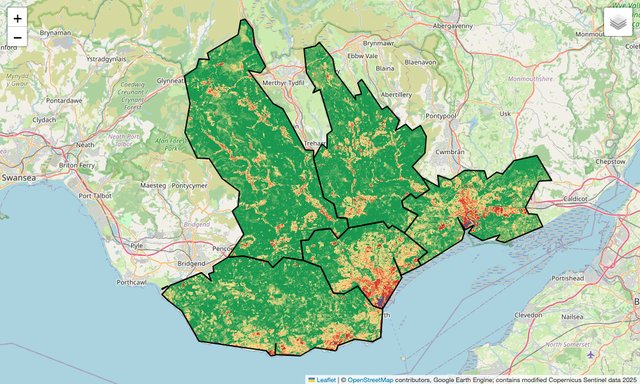

*NDVI from a Sentinel-2 median composite, May–August 2025. Contains modified Copernicus Sentinel data 2025, processed in Google Earth Engine; Local Authority District boundaries (December 2024), Office for National Statistics, Open Government Licence v3.0; basemap © OpenStreetMap contributors.*

### Think 5


**Interpretation.** Do the wind projects in the valleys north of Cardiff sit on **high-NDVI** (green) or **low-NDVI** (red) land? And the solar farms in the Vale of Glamorgan? What can an NDVI layer **not** tell you about whether a site suits a wind farm? Write two sentences for a reader who sees this map.

*Notes from the discussion:*

## Wrap-up

You used this week's three tools on one question: a filtered table → an interactive **Folium** map with layers → satellite **pixels as a table**, with NDVI by band maths → a **seaborn** boxplot that tests what NDVI can and can't separate → raster and vector on **one map**. Every step was checked before the next one used it.

The pixel table comes back in **Week 12**, where a model learns land cover from all the bands, not just NDVI.

## Optional homework

These practise the same skills; nothing new is needed.

1. **When did the UK drop below the world average?** From `owid_co2_cleaned.csv`, keep `"United Kingdom"` and `"World"` from 1990 onwards and draw `co2_per_capita` with `sns.lineplot(..., hue="country")`. In which year does the UK line first fall below the world line?
2. **Capacity, not count.** A boxplot of `capacity_mw` for each technology in `wales`. A few very large projects squash the boxes: add `ax.set_yscale("log")`. Which technology has the larger typical project?
3. **A water index.** Boxplot `NDWI` (already in `pixels`) by `land_cover`. Which land cover does NDWI separate best?
4. **Share your map.** `m.save("wales_projects.html")` writes your Step 2 map to a web page (in Colab: the *Files* panel).